Initial Dataset Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


Removed 31994 duplicate rows.
Cleaned Dataset Shape: (87392, 32)
Remaining missing values: 0


/tmp/ipykernel_3864/3566254103.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='hotel', palette='Set2')
/tmp/ipykernel_3864/3566254103.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='is_canceled', palette='coolwarm')
/tmp/ipykernel_3864/3566254103.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='hotel', y='adr', palette='Set3')


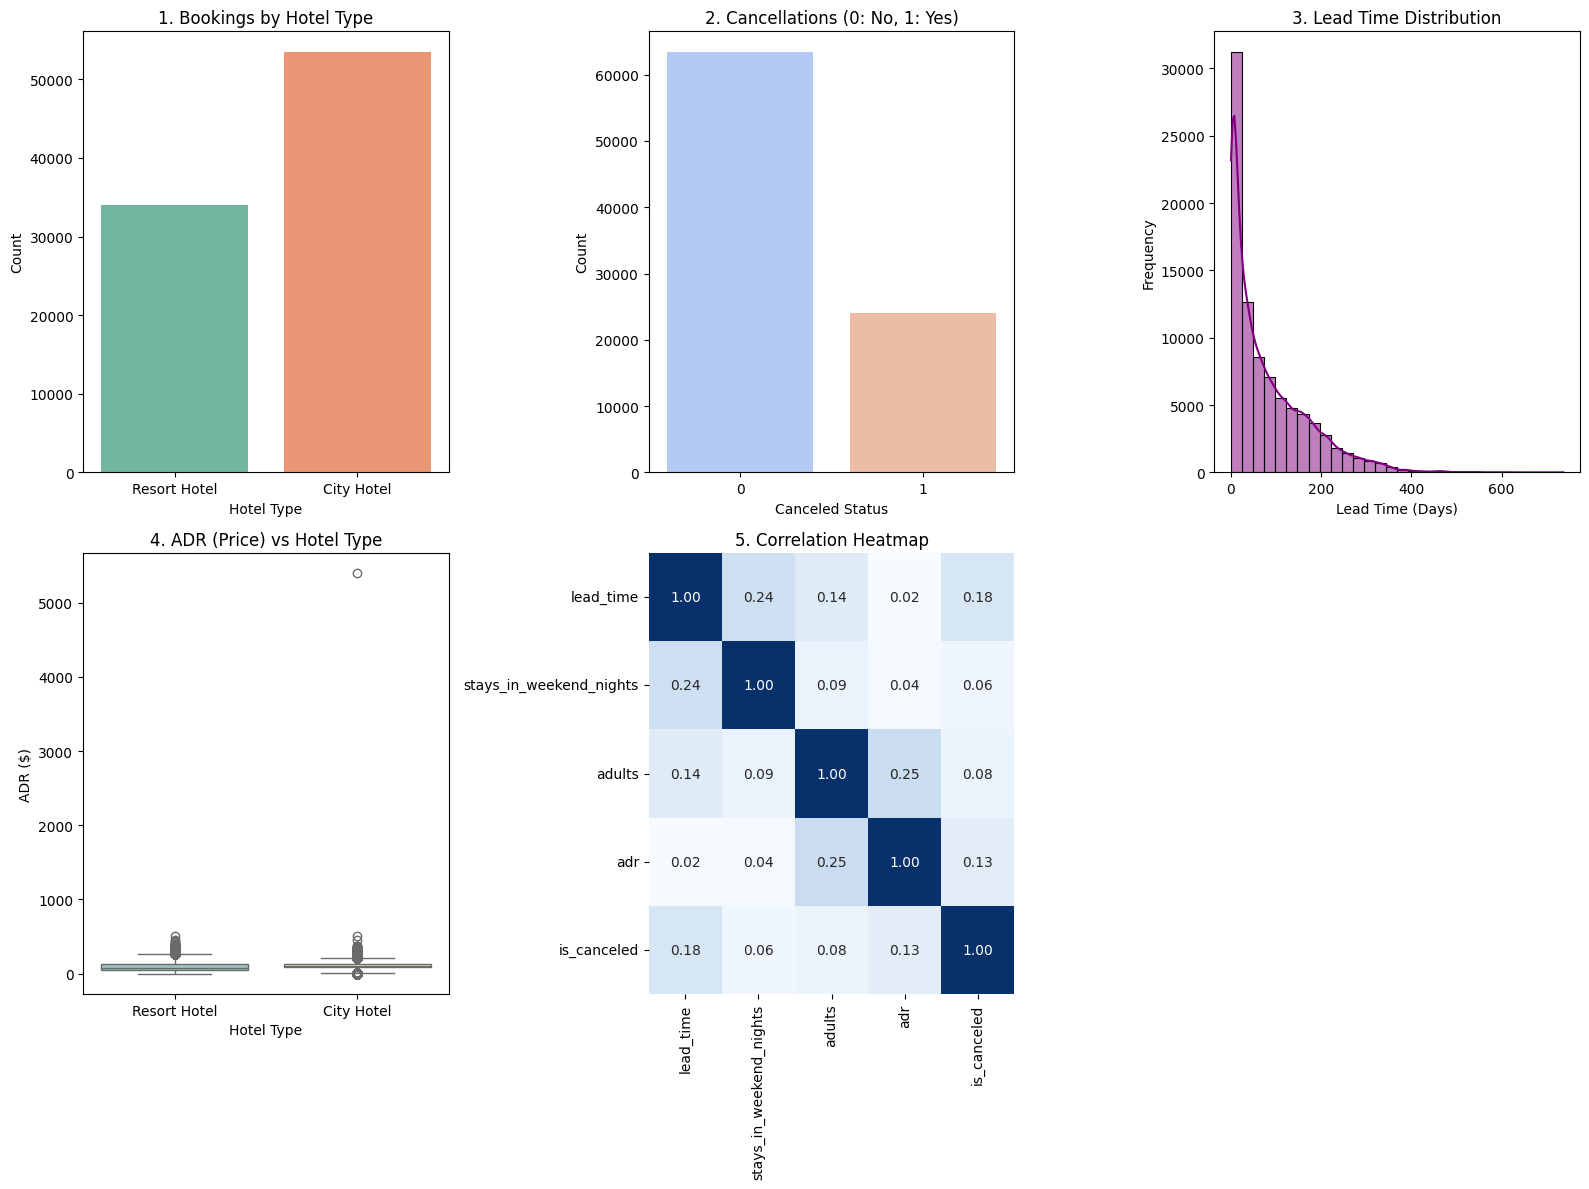


--- Statistical Summaries ---
          lead_time           adr  stays_in_weekend_nights
count  87392.000000  87392.000000             87392.000000
mean      79.894887    106.340758                 1.005275
std       86.052720     55.012457                 1.031928
min        0.000000     -6.380000                 0.000000
25%       11.000000     72.000000                 0.000000
50%       49.000000     98.100000                 1.000000
75%      125.000000    134.000000                 2.000000
max      737.000000   5400.000000                19.000000


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Load Dataset & Basic Assessment
# ==========================================
df = pd.read_csv('hotel_bookings.csv')
print("Initial Dataset Shape:", df.shape)
display(df.head(3))

# ==========================================
# 2. Data Cleaning Phase (Using Functions)
# ==========================================
def clean_hotel_data(data):
    df_clean = data.copy()

    # Handle missing values using safe fill methods
    df_clean['agent'] = df_clean['agent'].fillna(0)
    df_clean['company'] = df_clean['company'].fillna(0)
    df_clean['country'] = df_clean['country'].fillna('Unknown')

    # Drop rows with missing children if any
    df_clean = df_clean.dropna(subset=['children'])

    # Remove duplicate rows
    initial_rows = df_clean.shape[0]
    df_clean = df_clean.drop_duplicates()
    print(f"Removed {initial_rows - df_clean.shape[0]} duplicate rows.")

    return df_clean

df = clean_hotel_data(df)
print("Cleaned Dataset Shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())

# ==========================================
# 3. Exploratory Data Analysis & Visualizations
# ==========================================
plt.figure(figsize=(16, 12))

# 1. Count Plot - Hotel Types Distribution
plt.subplot(2, 3, 1)
sns.countplot(data=df, x='hotel', palette='Set2')
plt.title('1. Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Count')

# 2. Count Plot - Cancellations
plt.subplot(2, 3, 2)
sns.countplot(data=df, x='is_canceled', palette='coolwarm')
plt.title('2. Cancellations (0: No, 1: Yes)')
plt.xlabel('Canceled Status')
plt.ylabel('Count')

# 3. Histogram with KDE - Lead Time Distribution
plt.subplot(2, 3, 3)
sns.histplot(df['lead_time'], bins=30, kde=True, color='purple')
plt.title('3. Lead Time Distribution')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Frequency')

# 4. Box Plot - ADR (Price) vs Hotel Type
plt.subplot(2, 3, 4)
sns.boxplot(data=df, x='hotel', y='adr', palette='Set3')
plt.title('4. ADR (Price) vs Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('ADR ($)')

# 5. Correlation Heatmap - Numerical Variables
plt.subplot(2, 3, 5)
num_cols = ['lead_time', 'stays_in_weekend_nights', 'adults', 'adr', 'is_canceled']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='Blues', fmt='.2f', cbar=False)
plt.title('5. Correlation Heatmap')

plt.tight_layout()
plt.show()

# Statistical summary for key variables
print("\n--- Statistical Summaries ---")
print(df[['lead_time', 'adr', 'stays_in_weekend_nights']].describe())

### 📌 Research Questions & Key Findings

#### Q1: What increases cancellations?
* **Lead time:** Bookings made long before arrival cancel more often.
* **Special requests:** Guests with 0 special requests cancel more frequently.

#### Q2: Which hotel type is booked more and costs more?
* **Demand:** City Hotels have higher total bookings than Resort Hotels.
* **Price (ADR):** Resort Hotels are more expensive during summer, while City Hotels have steady prices all year.

#### Q3: When is the peak season?
* **Peak Months:** July and August (Summer holidays).